<a href="https://colab.research.google.com/github/cristiangromero/LGRT-PIA/blob/main/Regresion_Consumo_Combustible.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción del consumo de combustible de automóviles con Regresión Lineal
**Materia:** Principios de Inteligencia Artificial · **Parte 2 – Implementación práctica**

**Problema:** dado un auto (peso, potencia, cilindrada, año, origen…), estimar su consumo en **millas por galón (mpg)**. Es un problema de **regresión supervisada**: la variable objetivo (`mpg`) es continua y cada auto del dataset trae su valor real.

**Contexto de negocio:** una empresa de logística que renueva su flota o una automotriz en fase de diseño pueden estimar el consumo de un modelo *antes* de probarlo físicamente, y entender qué atributos lo condicionan más.

**Dataset:** *Auto MPG* (UCI Machine Learning Repository, versión de la librería seaborn). 398 autos de 1970-1982.

**Fases:** 1) Preparación de datos · 2) Análisis exploratorio (EDA) · 3) Entrenamiento · 4) Evaluación y predicción.

## FASE 1. Preparación de datos

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
autos = pd.read_csv(URL)
autos.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
autos.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


**Observaciones de la inspección inicial**
- 398 registros y 9 columnas. `horsepower` tiene valores nulos (el resto está completo).
- `origin` y `name` son texto. `name` es un identificador casi único (no generaliza), así que se descarta.
- `cylinders`, `model_year` y `origin` son categorías/ordinales encubiertas en columnas numéricas o de texto; hay que decidir cómo tratarlas.

In [ ]:
print(autos.isna().sum())
autos.describe().T

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.514573,7.815984,9.0,17.500,23.0,29.000,46.6
cylinders,398.0,5.454774,1.701004,3.0,4.000,4.0,8.000,8.0
displacement,398.0,193.425879,104.269838,68.0,104.250,148.5,262.000,455.0
horsepower,392.0,104.469388,38.491160,46.0,75.000,93.5,126.000,230.0
weight,398.0,2970.424623,846.841774,1613.0,2223.750,2803.5,3608.000,5140.0
acceleration,398.0,15.568090,2.757689,8.0,13.825,15.5,17.175,24.8
model_year,398.0,76.010050,3.697627,70.0,73.000,76.0,79.000,82.0


### 1.1 Valores faltantes
Faltan 6 valores de `horsepower` (1,5 % del dataset). Eliminar filas es una opción válida con tan pocos casos, pero hay una opción mejor: **imputar con la mediana** (robusta a outliers). Para evitar *data leakage*, la mediana se calcula **solo con los datos de entrenamiento**, por eso la imputación va dentro de un `Pipeline` en la Fase 3 y no acá.

### 1.2 Variables irrelevantes
`name` se elimina (identificador, sin poder predictivo general).

In [ ]:
autos = autos.drop(columns=["name"])
autos["origin"].value_counts()

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

### 1.3 Variables categóricas
`origin` (usa / japan / europe) es **nominal**: no hay orden entre países. Codificarla como 1, 2, 3 le impondría al modelo un orden inexistente, así que se usa **One-Hot Encoding** (una columna 0/1 por categoría). Esto se hace dentro del pipeline para que sea reproducible con datos nuevos.

`cylinders` se deja numérica (3, 4, 5, 6, 8): el orden y la magnitud sí tienen sentido.

### 1.4 Outliers
Detectamos valores atípicos con el criterio del rango intercuartílico (IQR) y boxplots.

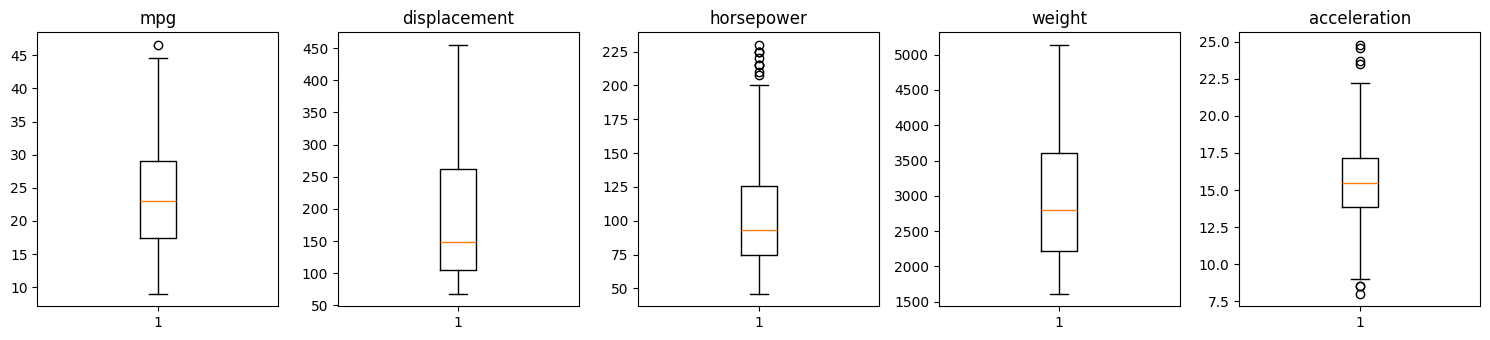

mpg           -> 1 valores fuera de 1.5*IQR (rango 46.6 a 46.6)
displacement  -> 0 valores fuera de 1.5*IQR (rango - a -)
horsepower    -> 10 valores fuera de 1.5*IQR (rango 208.0 a 230.0)
weight        -> 0 valores fuera de 1.5*IQR (rango - a -)
acceleration  -> 7 valores fuera de 1.5*IQR (rango 8.0 a 24.8)


In [ ]:
num = ["mpg", "displacement", "horsepower", "weight", "acceleration"]
fig, ax = plt.subplots(1, 5, figsize=(15, 3.5))
for a, c in zip(ax, num):
    a.boxplot(autos[c].dropna()); a.set_title(c)
plt.tight_layout(); plt.show()

def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return s[(s < q1 - 1.5*i) | (s > q3 + 1.5*i)]

for c in num:
    o = outliers_iqr(autos[c].dropna())
    print(f"{c:13s} -> {len(o)} valores fuera de 1.5*IQR (rango {o.min() if len(o) else '-'} a {o.max() if len(o) else '-'})")

**Decisión sobre outliers:** los pocos valores marcados (10 autos con `horsepower` > 208, 7 con `acceleration` extrema y un `mpg` de 46,6) son **autos reales**, no errores de carga: muscle cars de alta potencia y autos muy lentos. A diferencia del caso del maratón (`sp4week` > 1000 era un valor físicamente imposible), acá no hay justificación para eliminarlos. Se conservan. Criterio: *se elimina un outlier si es un error; si es un caso real, se conserva* y se vigila su efecto.

## FASE 2. Análisis exploratorio (EDA)

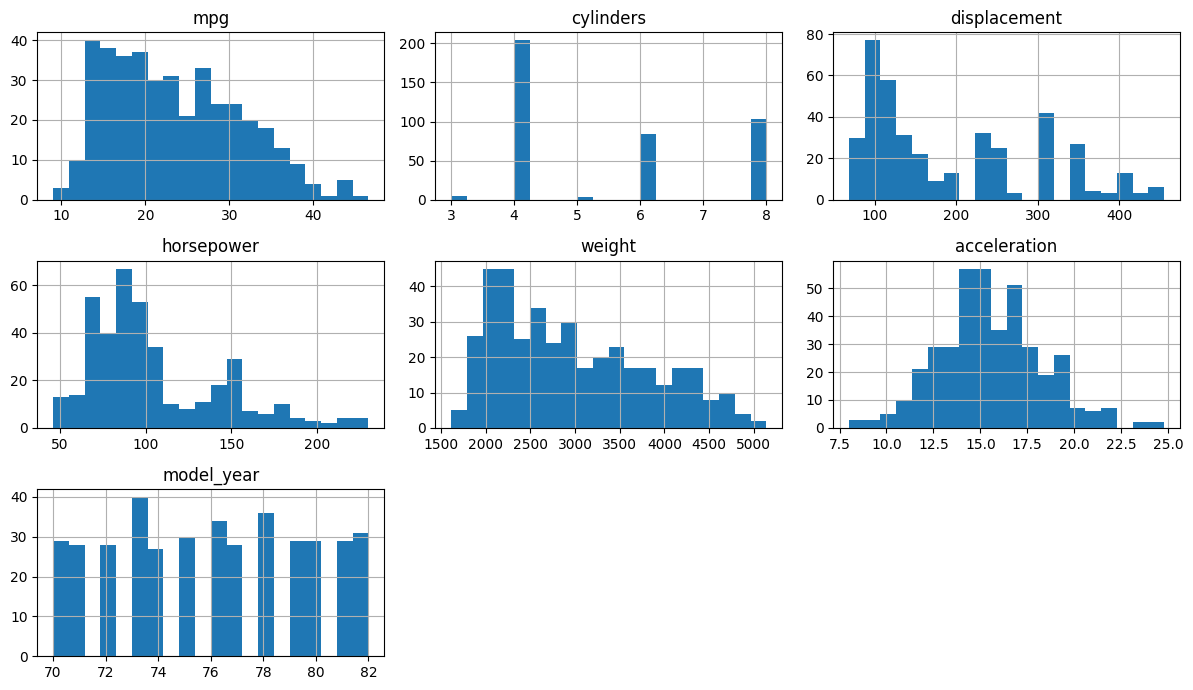

In [ ]:
autos.hist(figsize=(12, 7), bins=20); plt.tight_layout(); plt.show()

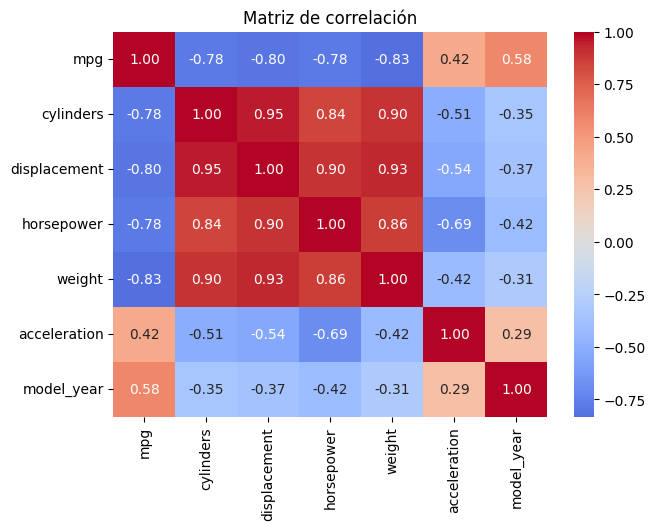

weight         -0.831741
displacement   -0.804203
horsepower     -0.778427
cylinders      -0.775396
acceleration    0.420289
model_year      0.579267
mpg             1.000000
Name: mpg, dtype: float64

In [ ]:
corr = autos.drop(columns="origin").corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación"); plt.show()
corr["mpg"].sort_values()

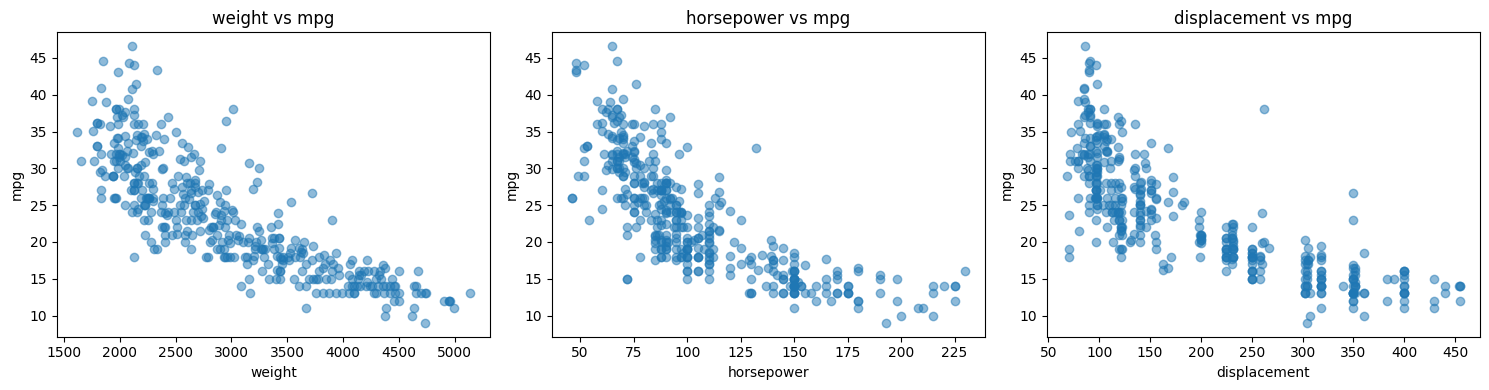

,count,mean,median
origin,,,
europe,70,27.9,26.5
japan,79,30.5,31.6
usa,249,20.1,18.5


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["weight", "horsepower", "displacement"]):
    a.scatter(autos[c], autos["mpg"], alpha=.5)
    a.set_xlabel(c); a.set_ylabel("mpg"); a.set_title(f"{c} vs mpg")
plt.tight_layout(); plt.show()

autos.groupby("origin")["mpg"].agg(["count", "mean", "median"]).round(1)

**Hallazgos del EDA**
1. `weight`, `displacement`, `horsepower` y `cylinders` tienen correlación **fuertemente negativa** con `mpg` (≈ -0,78 a -0,83): autos más pesados y potentes consumen más.
2. Esas cuatro variables están **muy correlacionadas entre sí** (**multicolinealidad**). Esto no arruina la capacidad predictiva, pero hace que los coeficientes individuales sean inestables e **inefectivos para interpretar**: el modelo puede repartir el efecto del "tamaño del auto" entre varias variables de forma arbitraria.
3. Los scatter plots muestran una relación **ligeramente curva** (convexa) entre `weight` y `mpg`, no perfectamente lineal. Es una pista de que una transformación del objetivo podría mejorar el ajuste (se prueba en la Fase 4).
4. `model_year` tiene correlación positiva (+0,58): los autos nuevos son más eficientes. Los autos de `usa` consumen más en promedio que los de `japan` y `europe`.

## FASE 3. Entrenamiento del modelo
### 3.1 División entrenamiento / prueba (80 / 20)
El conjunto de prueba se aparta **antes** de calcular medianas, codificar o entrenar: no debe influir en nada del proceso.

In [ ]:
from sklearn.model_selection import train_test_split

X = autos.drop(columns="mpg")
y = autos["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print(f"Entrenamiento: {len(X_train)} autos | Prueba: {len(X_test)} autos")

Entrenamiento: 318 autos | Prueba: 80 autos


### 3.2 Pipeline de preprocesamiento + modelo
Un `Pipeline` encadena imputación, One-Hot y regresión. Al llamar a `fit()` todo se aprende **solo con train**, y al llamar a `predict()` se aplica automáticamente a datos nuevos (equivalente a empaquetar el preprocesamiento junto al modelo, como se haría en producción).

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

num_cols = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cat_cols = ["origin"]

prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])

modelo = Pipeline([("prep", prep), ("reg", LinearRegression())])
modelo.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spa

In [ ]:
nombres = modelo.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(modelo.named_steps["reg"].coef_, index=nombres).round(4)
print("Intercepto:", round(modelo.named_steps["reg"].intercept_, 2))
coefs

Intercepto: -16.88


num__cylinders      -0.4004
num__displacement    0.0252
num__horsepower     -0.0209
num__weight         -0.0067
num__acceleration    0.1907
num__model_year      0.7653
cat__origin_japan    0.4811
cat__origin_usa     -2.6569
dtype: float64

**Lectura de coeficientes (con cautela).** Por ejemplo, `weight ≈ -0,0067` significa que, manteniendo el resto constante, cada libra extra reduce ~0,0067 mpg (1.000 lb ≈ -6,7 mpg). Y `model_year ≈ +0,77`: cada año de antigüedad menos suma ~0,8 mpg. Dada la multicolinealidad, los coeficientes de `displacement`, `horsepower` y `cylinders` no deben interpretarse de manera aislada.

## FASE 4. Evaluación y predicción

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluar(nombre, y_real, y_pred):
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    print(f"{nombre:12s} RMSE = {rmse:.2f} mpg | MAE = {mae:.2f} mpg | R² = {r2:.3f}")
    return rmse

pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
rmse_tr = evaluar("Entrenamiento", y_train, pred_train)
rmse_te = evaluar("Prueba", y_test, pred_test)
print(f"\nRMSE relativo sobre el mpg medio: {rmse_te / y.mean():.1%}")

Entrenamiento RMSE = 3.28 mpg | MAE = 2.48 mpg | R² = 0.821
Prueba       RMSE = 3.31 mpg | MAE = 2.70 mpg | R² = 0.827

RMSE relativo sobre el mpg medio: 14.1%


**Interpretación**
- **RMSE** está en las mismas unidades que el objetivo (**mpg**, no porcentaje): el modelo se equivoca típicamente por ~3 mpg. Sobre un consumo medio de ~23 mpg, eso es ≈ 14 % de error relativo.
- **MAE** es el error absoluto medio (menos sensible a errores grandes que el RMSE).
- **R²** indica qué proporción de la variabilidad de `mpg` explica el modelo (≈ 0,83).
- **Diagnóstico de overfitting:** el RMSE en train (3,28) y en test (3,31) es prácticamente igual (no hay brecha), así que el modelo **no está sobreajustado**. Con una regresión lineal de 8 variables y 318 ejemplos, el riesgo ya era bajo.

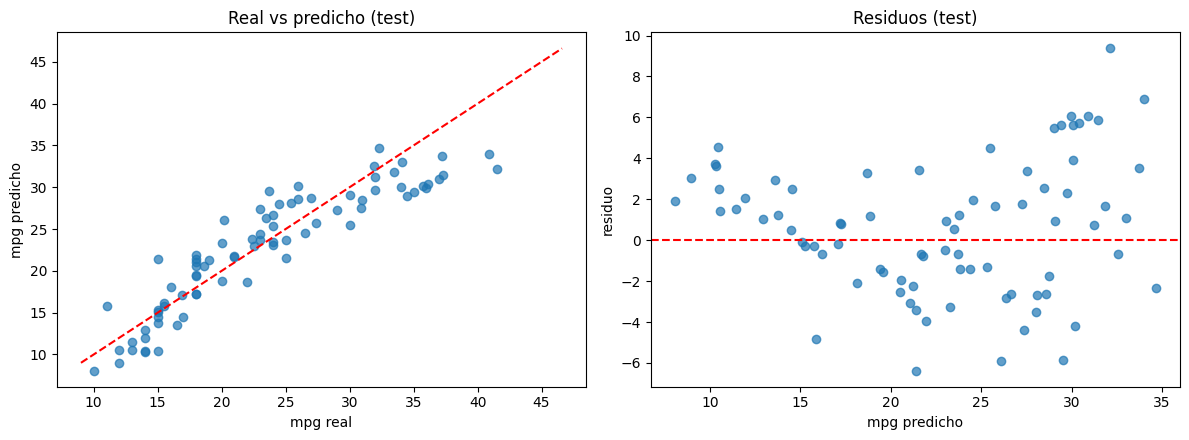

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred_test, alpha=.7)
lim = [y.min(), y.max()]; ax[0].plot(lim, lim, "r--")
ax[0].set_xlabel("mpg real"); ax[0].set_ylabel("mpg predicho"); ax[0].set_title("Real vs predicho (test)")

residuos = y_test - pred_test
ax[1].scatter(pred_test, residuos, alpha=.7); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("mpg predicho"); ax[1].set_ylabel("residuo"); ax[1].set_title("Residuos (test)")
plt.tight_layout(); plt.show()

Los residuos muestran un patrón en forma de **curva/embudo**: el modelo subestima o sobreestima sistemáticamente en los extremos y el error crece con el consumo. Es la señal de que la relación **no es perfectamente lineal** (lo anticipó el EDA).

### 4.1 Validación cruzada
Con solo 80 autos de prueba, un único split da una métrica inestable. La **validación cruzada de 5 particiones** entrena y evalúa 5 veces con distintos cortes y da una idea más confiable (promedio y dispersión).

In [ ]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=0)
cv = -cross_val_score(modelo, X, y, cv=kf, scoring="neg_root_mean_squared_error")
print("RMSE por partición:", cv.round(2))
print(f"RMSE medio: {cv.mean():.2f} ± {cv.std():.2f} mpg")

RMSE por partición: [3.31 3.57 3.78 3.08 3.1 ]
RMSE medio: 3.37 ± 0.27 mpg


### 4.2 Mejora: modelar `log(mpg)`
Dado que el consumo físico se comporta de forma multiplicativa (el efecto del peso es proporcional, no aditivo) y vimos curvatura en el EDA, se prueba entrenar sobre `log(mpg)` y luego convertir de vuelta. `TransformedTargetRegressor` lo hace automáticamente, y las métricas se calculan en mpg originales para poder compararlas.

In [ ]:
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep), ("reg", LinearRegression())]),
    func=np.log, inverse_func=np.exp)
modelo_log.fit(X_train, y_train)

print("Modelo base:")
evaluar("  Prueba", y_test, modelo.predict(X_test))
print("Modelo log(mpg):")
evaluar("  Prueba", y_test, modelo_log.predict(X_test))

cv_log = -cross_val_score(modelo_log, X, y, cv=kf, scoring="neg_root_mean_squared_error")
print(f"\nCV RMSE base:  {cv.mean():.2f} ± {cv.std():.2f}")
print(f"CV RMSE log:   {cv_log.mean():.2f} ± {cv_log.std():.2f}")

Modelo base:
  Prueba     RMSE = 3.31 mpg | MAE = 2.70 mpg | R² = 0.827
Modelo log(mpg):
  Prueba     RMSE = 2.93 mpg | MAE = 2.25 mpg | R² = 0.865

CV RMSE base:  3.37 ± 0.27
CV RMSE log:   2.98 ± 0.28


El RMSE baja de 3,37 a 2,98 mpg en validación cruzada (y de 3,31 a 2,93 en test), y el R² sube de 0,83 a 0,87. Como la mejora aparece también en la validación cruzada, no es un artefacto del corte particular de este split.

### 4.3 Predicción para autos nuevos
Se arman autos con valores **dentro del rango observado** (peso 1.613-5.140 lb, potencia 46-230 hp, años 70-82), para evitar extrapolar, algo que sí ocurría en el ejemplo del maratón (400 km/semana, muy fuera del rango).

In [ ]:
nuevos = pd.DataFrame([
    {"cylinders": 4, "displacement": 120, "horsepower": 90,  "weight": 2300, "acceleration": 15.5, "model_year": 80, "origin": "japan"},
    {"cylinders": 8, "displacement": 350, "horsepower": 165, "weight": 3900, "acceleration": 11.5, "model_year": 75, "origin": "usa"},
    {"cylinders": 6, "displacement": 200, "horsepower": 105, "weight": 3000, "acceleration": 16.0, "model_year": 78, "origin": "europe"},
])
nuevos["mpg_modelo_base"] = modelo.predict(nuevos).round(1)
nuevos["mpg_modelo_log"] = modelo_log.predict(nuevos.drop(columns="mpg_modelo_base")).round(1)
nuevos

,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg_modelo_base,mpg_modelo_log
0,4,120,90,2300,15.5,80,japan,32.0,31.4
1,8,350,165,3900,11.5,75,usa,16.2,15.6
2,6,200,105,3000,16.0,78,europe,26.3,24.4


## Conclusiones

1. **Resultado:** la regresión lineal múltiple explica ≈ 83 % de la variabilidad del consumo, con un error típico de **3,3 mpg** (RMSE en test; ±0,27 en validación cruzada). Con `log(mpg)` baja a **≈ 3,0 mpg** y R² ≈ 0,87.
2. **Sin overfitting:** el error en train y test es casi idéntico. El problema es más bien de *subajuste leve* (underfitting) por la no linealidad residual.
3. **Preparación:** se imputó `horsepower` con la mediana de train (sin data leakage), se aplicó One-Hot a `origin` y se conservaron los outliers por ser autos reales.
4. **Limitaciones:** multicolinealidad entre peso, cilindrada, potencia y cilindros (coeficientes poco interpretables individualmente); dataset antiguo (1970-82), por lo que no representa autos actuales, híbridos ni eléctricos; solo 398 registros.
5. **Mejoras posibles:** regularización (Ridge/Lasso) para la multicolinealidad, términos polinómicos de `weight`, o modelos no lineales (Random Forest) para comparar.